# GCSI Hourly Index Live Polling

## Integration guide: Global Commodity Sentiment Indices, hourly index

This notebook polls the **GCSI hourly index**, stores it in a local SQLite database, and builds a monitoring view
with a calibrated HIGH / NEUTRAL / LOW indicator. The same pattern, as three Docker services, is in
`app/live_index_polling/`.

### Output schema

| Field | Description |
|---|---|
| `ticker` | Commodity ticker, e.g. `BZ_COM` |
| `processed_at` | **End** of the hourly window (UTC), binned by when Permutable received the headline |
| `topic_name` | Topic label, `Sector::L1::L2` |
| `headline_count` | Distinct articles in the window |
| `sentiment_sum` | Sum of scores (−1 to +1 each) |
| `sentiment_std` | Sample standard deviation (0 when fewer than two headlines) |

`index_type` and `sentiment_type` are request parameters. The API does not return them, so this notebook writes both onto each row.

**Derived metrics**

```python
sentiment_avg = sentiment_sum / headline_count      # in [-1, +1]
```

### Rules this notebook follows

- `COMBINED` is the total of the three match types. **Never add `COMBINED` to the others.**
- Keep horizons separate. **Never add `sentiment_type`s together.**
- Topics are multi-label, so a ticker-level series built across topics is a **topic-weighted** average.
- Hours with no news are **omitted**, so rolling windows below are time-based (`'24h'`), not row-based.
- The newest bars can be **revised**. Every poll upserts, so a revised bar replaces the old one.

> **Disclaimer:** This notebook is provided for informational and research purposes only. Nothing here constitutes financial advice or a recommendation to buy, sell, or hold any asset. Sentiment scores are model outputs describing how news was judged at publication; they are not price forecasts.

In [ ]:
%pip install requests pandas numpy matplotlib seaborn

## Step 1: Configuration

In [2]:
import getpass
import os
import random
import sqlite3
import time
from datetime import date, datetime, timedelta, timezone
from pathlib import Path

import matplotlib
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns


def load_env_file() -> None:
    """Read KEY=VALUE pairs from the nearest .env file without overriding variables already set."""
    for base in [Path.cwd(), *Path.cwd().parents]:
        env_path = base / '.env'
        if env_path.exists():
            for line in env_path.read_text().splitlines():
                line = line.strip()
                if line and not line.startswith('#') and '=' in line:
                    key, value = line.split('=', 1)
                    os.environ.setdefault(key.strip(), value.strip().strip('"'))
            return


def get_api_key() -> str:
    load_env_file()
    key = os.environ.get('API_KEY') or os.environ.get('PERMUTABLE_API_KEY')
    if not key:
        key = getpass.getpass('Enter your Permutable AI API key: ')
    return key


API_KEY = get_api_key()

# ── Poll configuration ─────────────────────────────────────────────────────
TICKERS = ['BZ_COM', 'QO_COM', 'ZC_COM', 'EUA_COM']        # Brent, gold, corn, EU carbon
INDEX_TYPES = ['COMBINED']                                   # add EXPLICIT etc. for the breakdown in Step 7
SENTIMENT_TYPES = ['short_term', 'medium_term', 'long_term']
POLL_INTERVAL_SECONDS = 900
BACKFILL_DAYS = 7
DB_PATH = Path('gcsi_index_nb.db')

# ── Indicator ──────────────────────────────────────────────────────────────
SMOOTHING_WINDOW = '24h'      # time-based, so missing hours are handled correctly
MIN_HEADLINES = 5             # fewer topic-links than this in the window → no reading
THRESHOLD_MODE = 'percentile' # 'percentile' (calibrated from the data) or 'fixed'
UPPER_PCT, LOWER_PCT = 0.90, 0.10
FIXED_UPPER, FIXED_LOWER = 0.15, -0.15

# Display names for chart labels. Any ticker not listed is shown by its code.
TICKER_NAMES = {'BZ_COM': 'Brent Crude', 'QO_COM': 'Gold', 'ZC_COM': 'Corn', 'EUA_COM': 'EU Carbon'}


def ticker_label(ticker: str) -> str:
    return TICKER_NAMES.get(ticker, ticker)

BASE_URL = os.environ.get('BASE_URL', 'https://copilot-api.permutable.ai/v1')

# GCSI routes. The ticker and topic are query presets, not part of the path.
INDEX_LIVE_PATH = '/headlines/index/gcsi/live'
INDEX_HISTORICAL_PATH = '/headlines/index/gcsi/historical'
PAGE_LIMIT = 1000
MAX_LOOKBACK_DAYS = 90

calls = len(TICKERS) * len(INDEX_TYPES) * len(SENTIMENT_TYPES)
print(f'{calls} live requests per poll cycle; every request counts against your monthly quota.')

12 live requests per poll cycle; every request counts against your monthly quota.


## Step 2: Fetch and storage helpers

In [3]:
SESSION = requests.Session()
SESSION.headers.update({'x-api-key': API_KEY, 'accept': 'application/json'})


def api_get(path: str, params: dict | None = None, max_retries: int = 5):
    """GET a Permutable API path, backing off exponentially (with jitter) on 429 and 5xx responses."""
    params = {k: v for k, v in (params or {}).items() if v is not None}
    delay = 1.0
    for attempt in range(max_retries + 1):
        response = SESSION.get(BASE_URL + path, params=params, timeout=60)
        if response.status_code == 429 or response.status_code >= 500:
            if attempt == max_retries:
                response.raise_for_status()
            time.sleep(delay + random.uniform(0, delay / 2))
            delay *= 2
            continue
        if response.status_code in (401, 403):
            raise PermissionError(
                f'{response.status_code} on {path}: check the API key, and that your licence includes GCSI.'
            )
        response.raise_for_status()
        return response.json()


def _records(body) -> list[dict]:
    """Live endpoints return a list; historical endpoints return {data, has_more, next_token}."""
    return body['data'] if isinstance(body, dict) else body


def _stamp(records: list[dict], **dims) -> list[dict]:
    """Responses can omit the dimensions you asked for, so write them back onto each record."""
    for record in records:
        for key, value in dims.items():
            if value is not None:
                record.setdefault(key, value)
    return records


def _paginate(path: str, params: dict) -> list[dict]:
    params = {**params, 'limit': PAGE_LIMIT}
    rows: list[dict] = []
    while True:
        body = api_get(path, params)
        rows.extend(_records(body))
        if not (isinstance(body, dict) and body.get('has_more')):
            return rows
        params['next_token'] = body['next_token']


TOPIC_SEPARATOR = '::'  # Sector::L1::L2, the form the API returns


def normalise_topic(labels: pd.Series) -> pd.Series:
    """Write each label as sector, driver and topic joined by TOPIC_SEPARATOR, whatever separator the source used."""
    return labels.astype('string').str.replace(r'\s*(?:::|-)\s*', TOPIC_SEPARATOR, regex=True)


INDEX_VALUES = ['headline_count', 'sentiment_sum', 'sentiment_std']


def _index_params(ticker: str, index_type: str, sentiment_type: str) -> dict:
    # One ticker per call with every topic. A sector preset or ticker_preset=ALL can exceed the 1000-row live cap.
    return {'ticker_preset': ticker, 'topic_preset': 'ALL', 'index_type': index_type, 'sentiment_type': sentiment_type}


def fetch_live_index(ticker: str, index_type: str, sentiment_type: str) -> list[dict]:
    """Most recent hourly bars for one ticker. The live route is a plain list and the newest bars can still be revised."""
    body = api_get(INDEX_LIVE_PATH, _index_params(ticker, index_type, sentiment_type))
    return _stamp(_records(body), ticker=ticker, index_type=index_type, sentiment_type=sentiment_type)


def fetch_historical_index(
    ticker: str, index_type: str, sentiment_type: str, start: date, end: date | None = None
) -> list[dict]:
    """Hourly bars between start and end (inclusive dates), following next_token until has_more is false."""
    params = _index_params(ticker, index_type, sentiment_type)
    params.update({'start_date': start.isoformat(), 'end_date': end.isoformat() if end else None})
    rows = _paginate(INDEX_HISTORICAL_PATH, params)
    return _stamp(rows, ticker=ticker, index_type=index_type, sentiment_type=sentiment_type)


def to_index_frame(records: list[dict]) -> pd.DataFrame:
    """Records → DataFrame with a UTC processed_at and every value column present."""
    frame = pd.DataFrame(records)
    for column in ['ticker', 'topic_name', 'index_type', 'sentiment_type', 'processed_at', *INDEX_VALUES]:
        if column not in frame:
            frame[column] = np.nan
    frame['processed_at'] = pd.to_datetime(frame['processed_at'], utc=True)
    frame['topic_name'] = normalise_topic(frame['topic_name'])
    return frame


INDEX_COLUMNS = ['ticker', 'topic_name', 'index_type', 'sentiment_type', 'processed_at', *INDEX_VALUES, 'fetched_at']


def setup_database(db_path: Path = DB_PATH) -> None:
    with sqlite3.connect(db_path) as conn:
        conn.execute("""
            CREATE TABLE IF NOT EXISTS gcsi_index (
                ticker            TEXT NOT NULL,
                topic_name        TEXT NOT NULL,
                index_type        TEXT NOT NULL,
                sentiment_type    TEXT NOT NULL,
                processed_at  TEXT NOT NULL,
                headline_count    INTEGER,
                sentiment_sum     REAL,
                sentiment_std     REAL,
                fetched_at        TEXT,
                PRIMARY KEY (ticker, topic_name, index_type, sentiment_type, processed_at)
            )
        """)


def upsert_index(records: list[dict], db_path: Path = DB_PATH) -> int:
    """INSERT OR REPLACE, so a revised bar overwrites the earlier version of the same hour."""
    if not records:
        return 0
    fetched_at = datetime.now(timezone.utc).isoformat()
    rows = []
    for record in records:
        published = pd.Timestamp(record['processed_at'])
        published = published.tz_localize('UTC') if published.tzinfo is None else published.tz_convert('UTC')
        rows.append(tuple(
            published.isoformat() if col == 'processed_at' else fetched_at if col == 'fetched_at' else record.get(col)
            for col in INDEX_COLUMNS
        ))
    placeholders = ', '.join('?' * len(INDEX_COLUMNS))
    with sqlite3.connect(db_path) as conn:
        conn.executemany(f'INSERT OR REPLACE INTO gcsi_index ({", ".join(INDEX_COLUMNS)}) VALUES ({placeholders})', rows)
    return len(rows)


def poll_once(fetch, **kwargs) -> int:
    total = 0
    for ticker in TICKERS:
        for index_type in INDEX_TYPES:
            for sentiment_type in SENTIMENT_TYPES:
                try:
                    total += upsert_index(fetch(ticker, index_type, sentiment_type, **kwargs))
                except PermissionError:
                    raise
                except Exception as exc:
                    print(f'  {ticker}/{index_type}/{sentiment_type}: ERROR {exc}')
    return total


setup_database()
print('Database ready:', DB_PATH)

Database ready: gcsi_index_nb.db


## Step 3: Dry run (single live poll)

Check connectivity and the response shape before backfilling.

In [4]:
sample = fetch_live_index(TICKERS[0], INDEX_TYPES[0], SENTIMENT_TYPES[0])
print(f'{len(sample)} records for {TICKERS[0]} / {INDEX_TYPES[0]} / {SENTIMENT_TYPES[0]}')
if sample:
    print('Fields:', sorted(sample[0]))
    frame = to_index_frame(sample)
    frame['sentiment_avg'] = frame['sentiment_sum'] / frame['headline_count']
    display(frame.sort_values('processed_at').tail(10))

397 records for BZ_COM / COMBINED / short_term
Fields: ['headline_count', 'index_type', 'processed_at', 'sentiment_abs_sum', 'sentiment_std', 'sentiment_sum', 'sentiment_type', 'ticker', 'topic_id', 'topic_name']


,ticker,topic_name,topic_id,processed_at,headline_count,sentiment_sum,sentiment_abs_sum,sentiment_std,index_type,sentiment_type,sentiment_avg
12,BZ_COM,Energy::Macro::Policy & Regulation,db5adcb1-2453-542a-aa28-4cb4d7f18ad7,2026-11-10 10:00:00+00:00,3,-0.341,0.341,0.079,COMBINED,short_term,-0.113667
9,BZ_COM,Energy::Supply::Infrastructure & Logistics,7b82e680-15aa-5eb4-a28c-166d87317819,2026-11-10 10:00:00+00:00,19,0.590,3.038,0.195,COMBINED,short_term,0.031053
10,BZ_COM,Energy::Macro::Conflict,a05ae7bf-b955-5db5-929b-467e0d1ccb63,2026-11-10 10:00:00+00:00,246,22.181,52.031,0.207,COMBINED,short_term,0.090167
11,BZ_COM,Energy::Market::Forecasts,d905061b-2eed-53c8-a507-6ce8a834cd8b,2026-11-10 10:00:00+00:00,15,-3.752,3.912,0.240,COMBINED,short_term,-0.250133
13,BZ_COM,Energy::Demand::Global Consumption,df8ccf67-3f01-569c-b1a4-0aea06831153,2026-11-10 10:00:00+00:00,14,3.021,5.299,0.341,COMBINED,short_term,0.215786
14,BZ_COM,Energy::Macro::Economy & Central Banks,e7fa2e75-23b3-5f13-9866-b40500c219ba,2026-11-10 10:00:00+00:00,60,-0.114,5.528,0.125,COMBINED,short_term,-0.001900
15,BZ_COM,Energy::Demand::Industrial & Power,eceb110b-358f-5e01-8f0d-06cb80bdd8c1,2026-11-10 10:00:00+00:00,12,0.389,1.873,0.169,COMBINED,short_term,0.032417
16,BZ_COM,Energy::Macro::Producer Policy,f3851f6d-1103-5f49-a4b1-d59a80f8bfb6,2026-11-10 10:00:00+00:00,3,0.504,0.504,0.169,COMBINED,short_term,0.168000
8,BZ_COM,Energy::Macro::Global Trade & Sanctions,6453f0b7-8c67-536a-9649-d60d796ad720,2026-11-10 10:00:00+00:00,21,0.284,3.204,0.180,COMBINED,short_term,0.013524
0,BZ_COM,Energy::Supply::Refining,02222397-2ebc-546a-a34d-dcaf750ea3fa,2026-11-10 10:00:00+00:00,3,0.147,0.471,0.189,COMBINED,short_term,0.049000


## Step 4: Historical backfill

Fills the database with the last `BACKFILL_DAYS` so the charts have context. Historical requests page with
`next_token`. Running it again is safe, because rows are upserted.

In [5]:
RUN_BACKFILL = True

if RUN_BACKFILL:
    start = (datetime.now(timezone.utc) - timedelta(days=BACKFILL_DAYS)).date()
    n = poll_once(lambda t, i, s: fetch_historical_index(t, i, s, start))
    print(f'Backfill complete: {n:,} rows upserted.')

Backfill complete: 18,570 rows upserted.


## Step 5: Ticker-level sentiment by horizon

Rows for every topic are added per hour (topic-weighted). A 24-hour, time-based window then gives a weighted
rolling average: `Σ sentiment_sum / Σ headline_count` over the window. This is not a mean of hourly averages,
which would give a quiet hour the same weight as a busy one.

17,199 stored rows → 1,650 ticker-hours


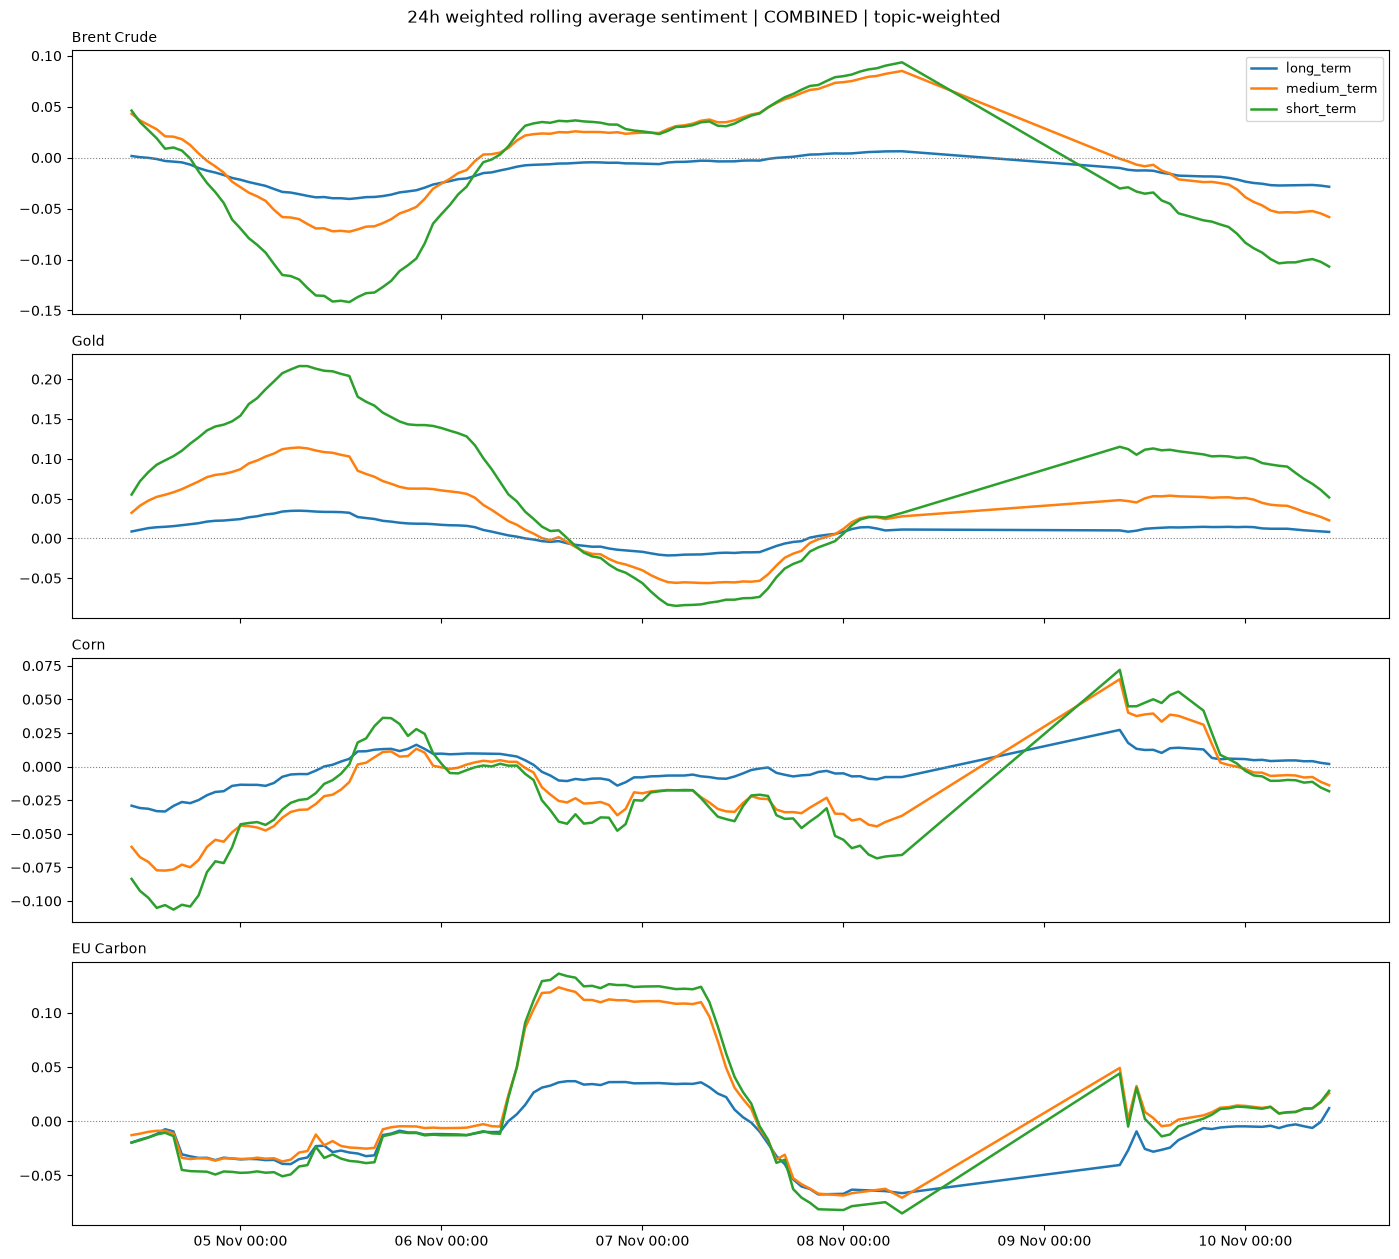

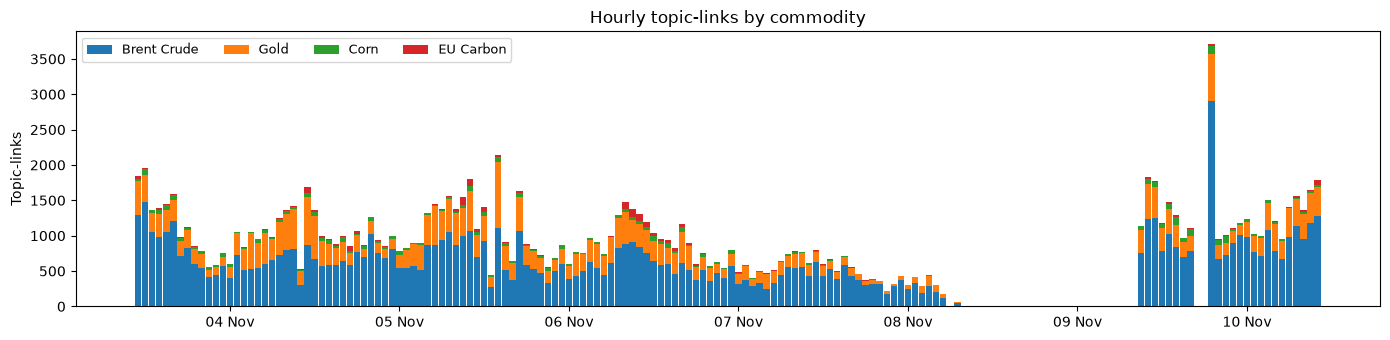

In [6]:
def load_db(hours: int = 24 * BACKFILL_DAYS, index_type: str = 'COMBINED') -> pd.DataFrame:
    since = (datetime.now(timezone.utc) - timedelta(hours=hours)).isoformat()
    with sqlite3.connect(DB_PATH) as conn:
        frame = pd.read_sql(
            'SELECT * FROM gcsi_index WHERE processed_at >= ? AND index_type = ?',
            conn, params=(since, index_type),
        )
    frame['processed_at'] = pd.to_datetime(frame['processed_at'], utc=True)
    return frame


def ticker_series(frame: pd.DataFrame) -> pd.DataFrame:
    hourly = (
        frame.groupby(['ticker', 'sentiment_type', 'processed_at'], as_index=False)[['headline_count', 'sentiment_sum']]
        .sum()
        .sort_values('processed_at')
    )
    out = []
    for (ticker, sentiment_type), group in hourly.groupby(['ticker', 'sentiment_type']):
        rolled = group.set_index('processed_at')[['headline_count', 'sentiment_sum']].rolling(SMOOTHING_WINDOW).sum()
        group = group.assign(
            window_count=rolled['headline_count'].values,
            sentiment_avg=group['sentiment_sum'] / group['headline_count'],
            sentiment_smooth=(rolled['sentiment_sum'] / rolled['headline_count']).values,
        )
        warm_up = group['processed_at'] < group['processed_at'].min() + pd.Timedelta(SMOOTHING_WINDOW)
        group.loc[(group['window_count'] < MIN_HEADLINES) | warm_up, 'sentiment_smooth'] = np.nan
        out.append(group)
    return pd.concat(out, ignore_index=True) if out else hourly


df = load_db()
series = ticker_series(df)
print(f'{len(df):,} stored rows → {len(series):,} ticker-hours')

if series.empty:
    print('No data yet: run the backfill above.')
else:
    tickers = [t for t in TICKERS if t in set(series['ticker'])]
    fig, axes = plt.subplots(len(tickers), 1, figsize=(14, 3.2 * len(tickers)), sharex=True, squeeze=False)
    for ax, ticker in zip(axes[:, 0], tickers):
        for sentiment_type, group in series[series['ticker'] == ticker].groupby('sentiment_type'):
            ax.plot(group['processed_at'], group['sentiment_smooth'], lw=1.8, label=sentiment_type)
        ax.axhline(0, color='grey', lw=0.8, ls=':')
        ax.set_title(ticker_label(ticker), loc='left', fontsize=10)
    axes[0, 0].legend(loc='upper right', fontsize=9)
    fig.suptitle(f'{SMOOTHING_WINDOW} weighted rolling average sentiment | COMBINED | topic-weighted')
    axes[-1, 0].xaxis.set_major_formatter(mdates.DateFormatter('%d %b %H:%M'))
    plt.tight_layout()
    plt.show()

    # News volume behind those readings: hourly topic-links per ticker (short term; every horizon has the same counts)
    volume = series[series['sentiment_type'] == 'short_term'].pivot_table(
        index='processed_at', columns='ticker', values='headline_count', aggfunc='sum'
    ).reindex(columns=tickers)
    fig, ax = plt.subplots(figsize=(14, 3.5))
    bottom = np.zeros(len(volume))
    for ticker in tickers:
        values = volume[ticker].fillna(0).to_numpy()
        ax.bar(volume.index, values, bottom=bottom, width=1 / 24 * 0.9, label=ticker_label(ticker))
        bottom += values
    ax.set_title('Hourly topic-links by commodity')
    ax.set_ylabel('Topic-links')
    ax.legend(loc='upper left', ncol=len(tickers), fontsize=9)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
    plt.tight_layout()
    plt.show()

## Step 6: Calibrated indicator

A fixed threshold that suits one commodity can misfire on another, so by default
the thresholds come from the distribution of each ticker's own smoothed series (`THRESHOLD_MODE = 'percentile'`).
With only a week of history the percentiles are a rough guide. For production, calibrate on a longer history:
the historical route serves up to 90 days per request.

,ticker,sentiment_type,processed_at,sentiment_smooth,window_count,lower,upper,indicator
0,BZ_COM,long_term,2026-11-10 10:00:00+00:00,-0.029,22105.0,-0.035,0.002,NEUTRAL
1,BZ_COM,medium_term,2026-11-10 10:00:00+00:00,-0.058,22105.0,-0.060,0.062,NEUTRAL
2,BZ_COM,short_term,2026-11-10 10:00:00+00:00,-0.107,22105.0,-0.118,0.065,NEUTRAL
3,EUA_COM,long_term,2026-11-10 10:00:00+00:00,0.012,334.0,-0.039,0.035,NEUTRAL
4,EUA_COM,medium_term,2026-11-10 10:00:00+00:00,0.026,334.0,-0.035,0.111,NEUTRAL
5,EUA_COM,short_term,2026-11-10 10:00:00+00:00,0.028,334.0,-0.048,0.124,NEUTRAL
6,QO_COM,long_term,2026-11-10 10:00:00+00:00,0.008,6881.0,-0.018,0.027,NEUTRAL
7,QO_COM,medium_term,2026-11-10 10:00:00+00:00,0.023,6881.0,-0.052,0.096,NEUTRAL
8,QO_COM,short_term,2026-11-10 10:00:00+00:00,0.051,6881.0,-0.074,0.177,NEUTRAL
9,ZC_COM,long_term,2026-11-10 10:00:00+00:00,0.002,1114.0,-0.016,0.012,NEUTRAL


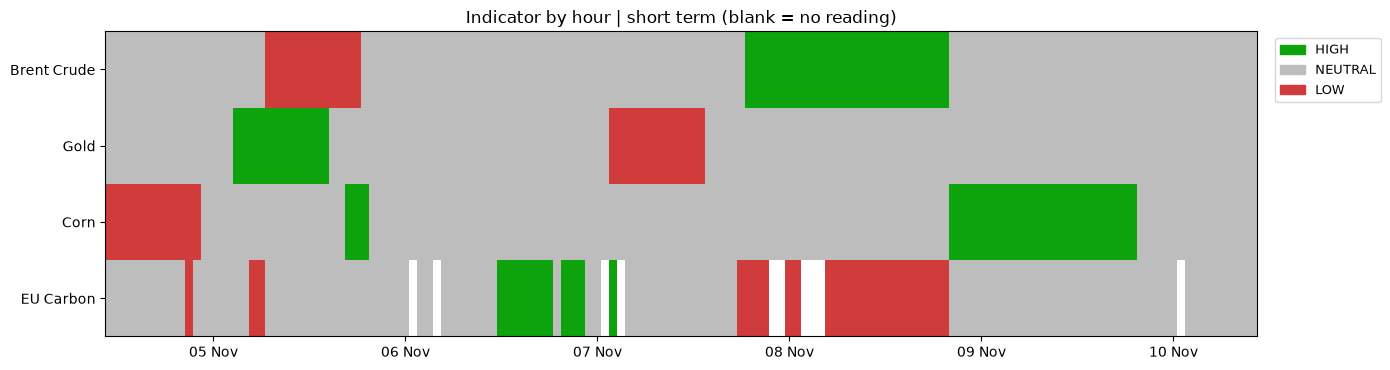

In [7]:
def add_indicator(frame: pd.DataFrame) -> pd.DataFrame:
    frame = frame.copy()
    frame['indicator'] = 'NO READING'
    for (ticker, sentiment_type), group in frame.groupby(['ticker', 'sentiment_type']):
        values = group['sentiment_smooth'].dropna()
        if values.empty:
            continue
        if THRESHOLD_MODE == 'percentile':
            upper, lower = values.quantile(UPPER_PCT), values.quantile(LOWER_PCT)
        else:
            upper, lower = FIXED_UPPER, FIXED_LOWER
        idx = group.index[group['sentiment_smooth'].notna()]
        frame.loc[idx, 'indicator'] = np.select(
            [frame.loc[idx, 'sentiment_smooth'] >= upper, frame.loc[idx, 'sentiment_smooth'] <= lower],
            ['HIGH', 'LOW'], 'NEUTRAL',
        )
        frame.loc[group.index, ['upper', 'lower']] = upper, lower
    return frame


if not series.empty:
    series = add_indicator(series)
    latest = series.sort_values('processed_at').groupby(['ticker', 'sentiment_type']).last().reset_index()
    display(latest[['ticker', 'sentiment_type', 'processed_at', 'sentiment_smooth', 'window_count',
                    'lower', 'upper', 'indicator']].round({'sentiment_smooth': 3, 'lower': 3, 'upper': 3}))

    # Indicator over time: one row per ticker, short term
    codes = {'LOW': -1, 'NEUTRAL': 0, 'HIGH': 1}
    timeline = (
        series[series['sentiment_type'] == 'short_term']
        .assign(code=lambda f: f['indicator'].map(codes))
        .pivot_table(index='ticker', columns='processed_at', values='code', aggfunc='last')
        .reindex([t for t in TICKERS if t in set(series['ticker'])])
    )
    cmap = matplotlib.colors.ListedColormap(['#d03b3b', '#bdbdbd', '#0ca30c'])
    fig, ax = plt.subplots(figsize=(14, 0.6 * len(timeline) + 1.4))
    ax.pcolormesh(timeline.columns, range(len(timeline)), timeline.to_numpy(), cmap=cmap, vmin=-1.5, vmax=1.5,
                  shading='nearest')
    ax.set_yticks(range(len(timeline)))
    ax.set_yticklabels([ticker_label(t) for t in timeline.index])
    ax.invert_yaxis()
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
    handles = [matplotlib.patches.Patch(color=colour, label=state) for colour, state in zip(cmap.colors[::-1], ['HIGH', 'NEUTRAL', 'LOW'])]
    ax.legend(handles=handles, loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=9)
    ax.set_title('Indicator by hour | short term (blank = no reading)')
    plt.tight_layout()
    plt.show()

## Step 7: Index-type breakdown (optional)

Add `'EXPLICIT'`, `'RELATED_ENTITY'` and `'MACROECONOMIC'` to `INDEX_TYPES`, then run the backfill again. This
shows whether a move came from news about the commodity itself, from linked entities, or from the macro
backdrop. Each line is its own series, and `COMBINED` is their volume-weighted blend.

In [8]:
frames = [load_db(index_type=it).assign(index_type=it) for it in ['EXPLICIT', 'RELATED_ENTITY', 'MACROECONOMIC', 'COMBINED']]
breakdown = pd.concat([f for f in frames if not f.empty], ignore_index=True) if any(not f.empty for f in frames) else pd.DataFrame()

if breakdown.empty or breakdown['index_type'].nunique() < 2:
    print('Only one index type stored: add more to INDEX_TYPES and run the backfill to see the breakdown.')
else:
    ticker = TICKERS[0]
    sub = breakdown[(breakdown['ticker'] == ticker) & (breakdown['sentiment_type'] == 'short_term')]
    fig, ax = plt.subplots(figsize=(14, 4))
    for index_type, group in sub.groupby('index_type'):
        smoothed = ticker_series(group)
        ax.plot(smoothed['processed_at'], smoothed['sentiment_smooth'], label=index_type)
    ax.axhline(0, color='grey', lw=0.8, ls=':')
    ax.set_title(f'{ticker_label(ticker)} | short_term | {SMOOTHING_WINDOW} weighted average by index type')
    ax.legend()
    plt.tight_layout()
    plt.show()

Only one index type stored: add more to INDEX_TYPES and run the backfill to see the breakdown.


## Step 8: Topic heatmap

Which topics drove the short-term reading over the last few days? Cells with fewer than `MIN_HEADLINES` topic-links
are left blank, because an average of one or two headlines is mostly noise.

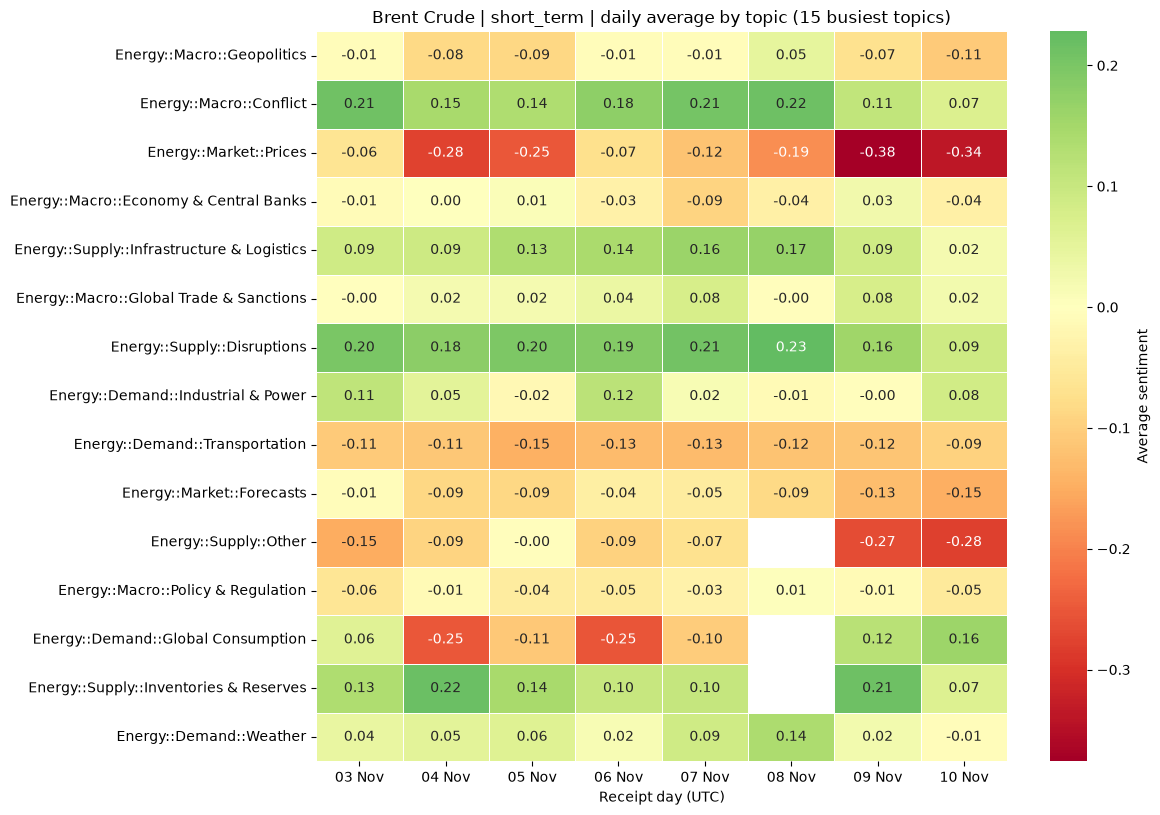

In [9]:
if not df.empty:
    ticker = TICKERS[0]
    sub = df[(df['ticker'] == ticker) & (df['sentiment_type'] == 'short_term')].copy()
    sub['day'] = (sub['processed_at'] - pd.Timedelta(hours=1)).dt.floor('D')
    grid = sub.groupby(['topic_name', 'day'])[['sentiment_sum', 'headline_count']].sum()
    avg = (grid['sentiment_sum'] / grid['headline_count']).where(grid['headline_count'] >= MIN_HEADLINES).unstack()
    top = sub.groupby('topic_name')['headline_count'].sum().nlargest(15).index
    avg = avg.reindex(top)
    avg.columns = avg.columns.strftime('%d %b')
    fig, ax = plt.subplots(figsize=(12, 0.45 * len(avg) + 1.5))
    sns.heatmap(avg, cmap='RdYlGn', center=0, annot=True, fmt='.2f', linewidths=0.4, ax=ax,
                cbar_kws={'label': 'Average sentiment'})
    ax.set_title(f'{ticker_label(ticker)} | short_term | daily average by topic (15 busiest topics)')
    ax.set_xlabel('Receipt day (UTC)')
    ax.set_ylabel('')
    plt.tight_layout()
    plt.show()

## Step 9: Live polling loop

Polls every `POLL_INTERVAL_SECONDS`. Each cycle upserts the latest bars, including revisions to recent hours.
Stop it with the Jupyter interrupt button.

In [10]:
RUN_POLLING_LOOP = False

if RUN_POLLING_LOOP:
    cycle = 0
    while True:
        cycle += 1
        started = datetime.now(timezone.utc)
        n = poll_once(fetch_live_index)
        elapsed = (datetime.now(timezone.utc) - started).total_seconds()
        print(f'[{cycle}] {started:%H:%M:%S} UTC: {n} rows upserted in {elapsed:.1f}s')
        time.sleep(max(0, POLL_INTERVAL_SECONDS - elapsed))
else:
    print('Polling loop disabled: set RUN_POLLING_LOOP = True to start it.')

Polling loop disabled: set RUN_POLLING_LOOP = True to start it.
